In [1]:
# FLA TASK 2 - AUTOMATA VALIDATION SYSTEM

# Install Graphviz for automata diagrams
!apt-get -qq install graphviz
!pip -q install graphviz

# Import required libraries
from graphviz import Digraph
from IPython.display import display, Markdown
from collections import deque
import string

print("FLA Task 2 environment is ready!")
print("Required libraries imported successfully.")

FLA Task 2 environment is ready!
Required libraries imported successfully.


In [3]:
class DFA:
    def __init__(self, states, alphabet, transitions,
                 start_state, accepting_states):

        self.states = set(states)
        self.alphabet = set(alphabet)
        self.transitions = transitions
        self.start_state = start_state
        self.accepting_states = set(accepting_states)

    def process(self, input_string):
        current_state = self.start_state
        trace = [current_state]

        for symbol in input_string:

            if symbol not in self.alphabet:
                return False, trace

            next_state = self.transitions.get(
                (current_state, symbol)
            )

            if next_state is None:
                return False, trace

            current_state = next_state
            trace.append(current_state)

        return current_state in self.accepting_states, trace

    def accepts(self, input_string):
        result, _ = self.process(input_string)
        return result


print("DFA engine created successfully!")

DFA engine created successfully!


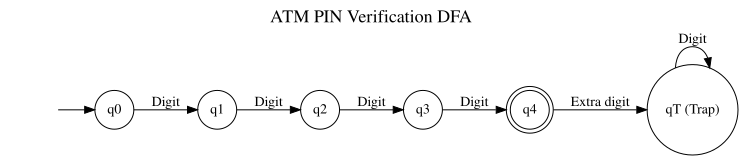


--- ACCEPTED TEST CASES ---

PIN: 1234
State path: q0 -> q1 -> q2 -> q3 -> q4
Result: ACCEPTED

PIN: 0000
State path: q0 -> q1 -> q2 -> q3 -> q4
Result: ACCEPTED

PIN: 9876
State path: q0 -> q1 -> q2 -> q3 -> q4
Result: ACCEPTED

PIN: 4567
State path: q0 -> q1 -> q2 -> q3 -> q4
Result: ACCEPTED

PIN: 1111
State path: q0 -> q1 -> q2 -> q3 -> q4
Result: ACCEPTED

--- REJECTED TEST CASES ---

PIN: 123
State path: q0 -> q1 -> q2 -> q3
Result: REJECTED

PIN: 12345
State path: q0 -> q1 -> q2 -> q3 -> q4 -> qT
Result: REJECTED

PIN: 12A4
State path: q0 -> q1 -> q2
Result: REJECTED

PIN: abcd
State path: q0
Result: REJECTED

PIN: 1 23
State path: q0 -> q1
Result: REJECTED

ATM PIN: ALL TESTS PASSED!


In [4]:
# ATM PIN VERIFICATION DFA

class ATMValidator:

    def __init__(self):
        digits = set("0123456789")

        states = {"q0", "q1", "q2", "q3", "q4", "qT"}
        transitions = {}

        # Exactly four digits
        for i in range(4):
            for digit in digits:
                transitions[(f"q{i}", digit)] = f"q{i+1}"

        # Extra digits lead to trap state
        for digit in digits:
            transitions[("q4", digit)] = "qT"
            transitions[("qT", digit)] = "qT"

        self.dfa = DFA(
            states,
            digits,
            transitions,
            "q0",
            {"q4"}
        )

    def validate(self, pin):
        accepted, trace = self.dfa.process(pin)

        print("\nPIN:", pin)
        print("State path:", " -> ".join(trace))
        print("Result:", "ACCEPTED" if accepted else "REJECTED")

        return accepted


# Create validator
atm = ATMValidator()


# Generate ATM DFA diagram
g = Digraph("ATM_PIN_DFA")

g.attr(rankdir="LR", label="ATM PIN Verification DFA",
       labelloc="t", fontsize="18")

g.attr("node", shape="circle")

g.node("start", "", shape="none")
g.node("q0")
g.node("q1")
g.node("q2")
g.node("q3")
g.node("q4", shape="doublecircle")
g.node("qT", "qT (Trap)")

g.edge("start", "q0")
g.edge("q0", "q1", label="Digit")
g.edge("q1", "q2", label="Digit")
g.edge("q2", "q3", label="Digit")
g.edge("q3", "q4", label="Digit")
g.edge("q4", "qT", label="Extra digit")
g.edge("qT", "qT", label="Digit")

display(g)


# Test cases
accepted_pins = ["1234", "0000", "9876", "4567", "1111"]
rejected_pins = ["123", "12345", "12A4", "abcd", "1 23"]

print("\n--- ACCEPTED TEST CASES ---")
for pin in accepted_pins:
    assert atm.validate(pin)

print("\n--- REJECTED TEST CASES ---")
for pin in rejected_pins:
    assert not atm.validate(pin)

print("\nATM PIN: ALL TESTS PASSED!")

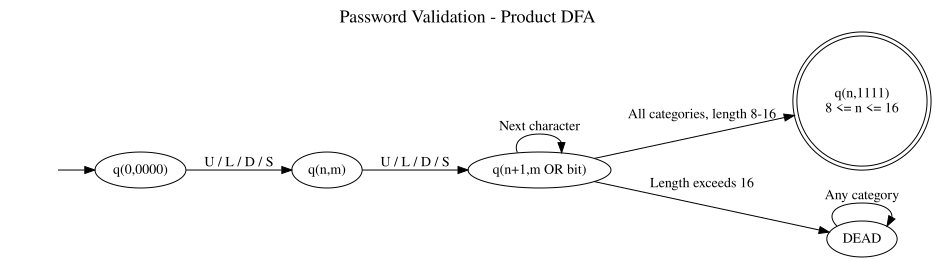


--- ACCEPTED PASSWORDS ---

Password: Abcdef1@
Categories: ULLLLLDS
States visited: 9
Result: ACCEPTED

Password: Hello123!
Categories: ULLLLDDDS
States visited: 10
Result: ACCEPTED

Password: Welcome1#
Categories: ULLLLLLDS
States visited: 10
Result: ACCEPTED

Password: Test1234$
Categories: ULLLDDDDS
States visited: 10
Result: ACCEPTED

Password: GoodPass9@
Categories: ULLLULLLDS
States visited: 11
Result: ACCEPTED

--- REJECTED PASSWORDS ---

Password: PASSWORD1@
Categories: UUUUUUUUDS
States visited: 11
Result: REJECTED

Password: password1@
Categories: LLLLLLLLDS
States visited: 11
Result: REJECTED

Password: Abcdefgh@
Categories: ULLLLLLLS
States visited: 10
Result: REJECTED

Password: Ab1@
Categories: ULDS
States visited: 5
Result: REJECTED

Password: Abcdefghijklmnop1@
Categories: ULLLLLLLLLLLLLLLDS
States visited: 19
Result: REJECTED

PASSWORD VALIDATION: ALL TESTS PASSED!


In [5]:
# PASSWORD VALIDATION - PRODUCT DFA

class PasswordValidator:

    def __init__(self):

        self.alphabet = {"U", "L", "D", "S"}

        bits = {
            "U": 1,
            "L": 2,
            "D": 4,
            "S": 8
        }

        states = {
            (length, mask)
            for length in range(17)
            for mask in range(16)
        }

        states.add("DEAD")
        transitions = {}

        for length in range(17):
            for mask in range(16):

                state = (length, mask)

                for category in self.alphabet:

                    if length == 16:
                        transitions[(state, category)] = "DEAD"

                    else:
                        transitions[(state, category)] = (
                            length + 1,
                            mask | bits[category]
                        )

        for category in self.alphabet:
            transitions[("DEAD", category)] = "DEAD"

        accepting_states = {
            (length, 15)
            for length in range(8, 17)
        }

        self.dfa = DFA(
            states,
            self.alphabet,
            transitions,
            (0, 0),
            accepting_states
        )

    def classify(self, char):

        if char.isascii() and char.isupper():
            return "U"

        elif char.isascii() and char.islower():
            return "L"

        elif char.isascii() and char.isdigit():
            return "D"

        elif char in string.punctuation:
            return "S"

        return "X"

    def validate(self, password):

        categories = ""

        for char in password:
            category = self.classify(char)

            if category == "X":
                print("\nPassword:", password)
                print("Result: REJECTED (Unsupported character)")
                return False

            categories += category

        accepted, trace = self.dfa.process(categories)

        print("\nPassword:", password)
        print("Categories:", categories)
        print("States visited:", len(trace))
        print("Result:", "ACCEPTED" if accepted else "REJECTED")

        return accepted


password_validator = PasswordValidator()


# PRODUCT DFA DIAGRAM
# Representative state-family diagram of the implemented DFA

g = Digraph("Password_Product_DFA")

g.attr(rankdir="LR",
       label="Password Validation - Product DFA",
       labelloc="t", fontsize="18")

g.node("start", "", shape="none")

g.node("q0", "q(0,0000)")
g.node("q1", "q(n,m)")
g.node("q2", "q(n+1,m OR bit)")
g.node("qA", "q(n,1111)\\n8 <= n <= 16",
       shape="doublecircle")
g.node("dead", "DEAD")

g.edge("start", "q0")
g.edge("q0", "q1", label="U / L / D / S")
g.edge("q1", "q2", label="U / L / D / S")
g.edge("q2", "q2", label="Next character")
g.edge("q2", "qA", label="All categories, length 8-16")
g.edge("q2", "dead", label="Length exceeds 16")
g.edge("dead", "dead", label="Any category")

display(g)


# TEST CASES

accepted_passwords = [
    "Abcdef1@",
    "Hello123!",
    "Welcome1#",
    "Test1234$",
    "GoodPass9@"
]

rejected_passwords = [
    "PASSWORD1@",
    "password1@",
    "Abcdefgh@",
    "Ab1@",
    "Abcdefghijklmnop1@"
]

print("\n--- ACCEPTED PASSWORDS ---")

for password in accepted_passwords:
    assert password_validator.validate(password)

print("\n--- REJECTED PASSWORDS ---")

for password in rejected_passwords:
    assert not password_validator.validate(password)

print("\nPASSWORD VALIDATION: ALL TESTS PASSED!")

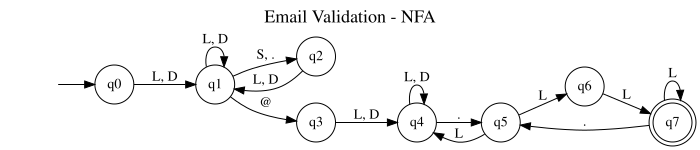


--- ACCEPTED EMAILS ---

Email: john.doe@example.com
Converted symbols: LLLL.LLL@LLLLLLL.LLL
Result: ACCEPTED

Email: a_b-1@sub.example.co
Converted symbols: LSLSD@LLL.LLLLLLL.LL
Result: ACCEPTED

Email: user123@mail.in
Converted symbols: LLLLDDD@LLLL.LL
Result: ACCEPTED

Email: x.y@abc.org
Converted symbols: L.L@LLL.LLL
Result: ACCEPTED

Email: first_last@domain.net
Converted symbols: LLLLLSLLLL@LLLLLL.LLL
Result: ACCEPTED

--- REJECTED EMAILS ---

Email: @example.com
Converted symbols: @LLLLLLL.LLL
Result: REJECTED

Email: john..doe@example.com
Converted symbols: LLLL..LLL@LLLLLLL.LLL
Result: REJECTED

Email: john@localhost
Converted symbols: LLLL@LLLLLLLLL
Result: REJECTED

Email: john@example.c
Converted symbols: LLLL@LLLLLLL.L
Result: REJECTED

Email: john@example.123
Converted symbols: LLLL@LLLLLLL.DDD
Result: REJECTED

EMAIL VALIDATION: ALL TESTS PASSED!

Reachable DFA states: 9


In [6]:
# EMAIL VALIDATION USING NFA AND DFA CONVERSION

class EmailValidator:

    def __init__(self):

        self.states = {
            "q0", "q1", "q2", "q3",
            "q4", "q5", "q6", "q7"
        }

        self.alphabet = {"L", "D", "S", "@", ".", "X"}
        self.start_state = "q0"
        self.accepting_states = {"q7"}

        self.transitions = {}

        def add(source, symbol, *destinations):
            self.transitions[(source, symbol)] = set(destinations)

        # Local part
        add("q0", "L", "q1")
        add("q0", "D", "q1")

        add("q1", "L", "q1")
        add("q1", "D", "q1")

        # Local part separators
        add("q1", "S", "q2")
        add("q1", ".", "q2")

        add("q2", "L", "q1")
        add("q2", "D", "q1")

        # @ symbol
        add("q1", "@", "q3")

        # Domain
        add("q3", "L", "q4")
        add("q3", "D", "q4")

        add("q4", "L", "q4")
        add("q4", "D", "q4")
        add("q4", ".", "q5")

        # NFA branching
        add("q5", "L", "q4", "q6")

        # Final domain extension
        add("q6", "L", "q7")
        add("q7", "L", "q7")
        add("q7", ".", "q5")

        # Convert NFA to DFA
        self.dfa = self.convert_to_dfa()

    def classify(self, char):

        if char.isascii() and char.isalpha():
            return "L"

        if char.isascii() and char.isdigit():
            return "D"

        if char in "_-":
            return "S"

        if char == "@":
            return "@"

        if char == ".":
            return "."

        return "X"

    def move(self, state_set, symbol):

        result = set()

        for state in state_set:
            result.update(
                self.transitions.get((state, symbol), set())
            )

        return frozenset(result)

    def convert_to_dfa(self):

        start = frozenset({self.start_state})

        dfa_states = {start}
        dfa_transitions = {}

        queue = deque([start])

        while queue:

            current = queue.popleft()

            for symbol in self.alphabet:

                next_state = self.move(current, symbol)

                dfa_transitions[(current, symbol)] = next_state

                if next_state not in dfa_states:
                    dfa_states.add(next_state)
                    queue.append(next_state)

        accepting = {
            state for state in dfa_states
            if state & self.accepting_states
        }

        return DFA(
            dfa_states,
            self.alphabet,
            dfa_transitions,
            start,
            accepting
        )

    def validate(self, email):

        symbols = "".join(
            self.classify(char) for char in email
        )

        accepted = self.dfa.accepts(symbols)

        print("\nEmail:", email)
        print("Converted symbols:", symbols)
        print("Result:", "ACCEPTED" if accepted else "REJECTED")

        return accepted


email_validator = EmailValidator()


# DISPLAY NFA DIAGRAM

g = Digraph("Email_NFA")

g.attr(
    rankdir="LR",
    label="Email Validation - NFA",
    labelloc="t",
    fontsize="18"
)

g.node("start", "", shape="none")

for state in ["q0", "q1", "q2", "q3", "q4", "q5", "q6"]:
    g.node(state, shape="circle")

g.node("q7", shape="doublecircle")

g.edge("start", "q0")

g.edge("q0", "q1", label="L, D")
g.edge("q1", "q1", label="L, D")
g.edge("q1", "q2", label="S, .")
g.edge("q2", "q1", label="L, D")
g.edge("q1", "q3", label="@")
g.edge("q3", "q4", label="L, D")
g.edge("q4", "q4", label="L, D")
g.edge("q4", "q5", label=".")
g.edge("q5", "q4", label="L")
g.edge("q5", "q6", label="L")
g.edge("q6", "q7", label="L")
g.edge("q7", "q7", label="L")
g.edge("q7", "q5", label=".")

display(g)


# TEST CASES

accepted_emails = [
    "john.doe@example.com",
    "a_b-1@sub.example.co",
    "user123@mail.in",
    "x.y@abc.org",
    "first_last@domain.net"
]

rejected_emails = [
    "@example.com",
    "john..doe@example.com",
    "john@localhost",
    "john@example.c",
    "john@example.123"
]

print("\n--- ACCEPTED EMAILS ---")

for email in accepted_emails:
    assert email_validator.validate(email)

print("\n--- REJECTED EMAILS ---")

for email in rejected_emails:
    assert not email_validator.validate(email)

print("\nEMAIL VALIDATION: ALL TESTS PASSED!")

print("\nReachable DFA states:",
      len(email_validator.dfa.states))

In [8]:
# FINAL VALIDATION

print("===== ATM PIN TEST =====")
atm.validate("1234")

print("\n===== PASSWORD TEST =====")
password_validator.validate("Abcdef1@")

print("\n===== EMAIL TEST =====")
email_validator.validate("john@example.com")

print("\n===== DFA INFORMATION =====")
print("ATM DFA states:", atm.dfa.states)
print("Password DFA states:", len(password_validator.dfa.states))
print("Email DFA states:", len(email_validator.dfa.states))

print("\nALL THREE VALIDATORS ARE WORKING!")

===== ATM PIN TEST =====

PIN: 1234
State path: q0 -> q1 -> q2 -> q3 -> q4
Result: ACCEPTED

===== PASSWORD TEST =====

Password: Abcdef1@
Categories: ULLLLLDS
States visited: 9
Result: ACCEPTED

===== EMAIL TEST =====

Email: john@example.com
Converted symbols: LLLL@LLLLLLL.LLL
Result: ACCEPTED

===== DFA INFORMATION =====
ATM DFA states: {'q4', 'q0', 'q1', 'q2', 'q3', 'qT'}
Password DFA states: 273
Email DFA states: 9

ALL THREE VALIDATORS ARE WORKING!


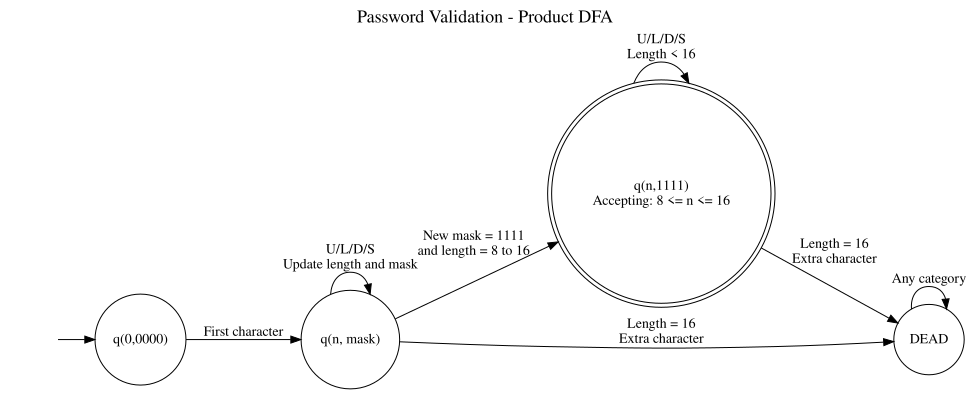

Password DFA diagram generated.


In [12]:
# CORRECTED PASSWORD PRODUCT DFA DIAGRAM

password_graph = Digraph("Password_Product_DFA")

password_graph.attr(
    rankdir="LR",
    label="Password Validation - Product DFA",
    labelloc="t",
    fontsize="18"
)

password_graph.attr("node", shape="circle")

password_graph.node("start", "", shape="none")
password_graph.node("q0", "q(0,0000)")
password_graph.node("q", "q(n, mask)")
password_graph.node(
    "accept",
    "q(n,1111)\nAccepting: 8 <= n <= 16",
    shape="doublecircle"
)
password_graph.node("dead", "DEAD")

password_graph.edge("start", "q0")

password_graph.edge(
    "q0", "q",
    label="First character"
)

password_graph.edge(
    "q", "q",
    label="U/L/D/S\nUpdate length and mask"
)

password_graph.edge(
    "q", "accept",
    label="New mask = 1111\nand length = 8 to 16"
)

password_graph.edge(
    "accept", "accept",
    label="U/L/D/S\nLength < 16"
)

password_graph.edge(
    "q", "dead",
    label="Length = 16\nExtra character"
)

password_graph.edge(
    "accept", "dead",
    label="Length = 16\nExtra character"
)

password_graph.edge(
    "dead", "dead",
    label="Any category"
)

display(password_graph)

print("Password DFA diagram generated.")

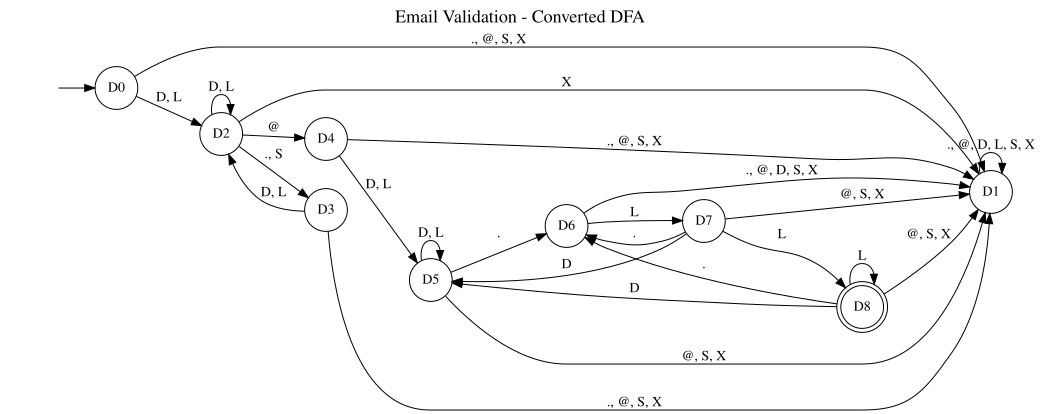

In [11]:
# EMAIL NFA-TO-DFA CONVERSION DIAGRAM

email_dfa_graph = Digraph("Email_Converted_DFA")

email_dfa_graph.attr(
    rankdir="LR",
    label="Email Validation - Converted DFA",
    labelloc="t",
    fontsize="18"
)

email_dfa_graph.attr("node", shape="circle")

start = email_validator.dfa.start_state
queue = deque([start])
visited = {start}
state_names = {start: "D0"}
edges = {}

while queue:
    current = queue.popleft()

    for symbol in sorted(email_validator.dfa.alphabet):
        next_state = email_validator.dfa.transitions[(current, symbol)]

        if next_state not in visited:
            visited.add(next_state)
            queue.append(next_state)
            state_names[next_state] = f"D{len(state_names)}"

        key = (current, next_state)
        edges.setdefault(key, []).append(symbol)

email_dfa_graph.node("start", "", shape="none")

for state, name in state_names.items():
    shape = (
        "doublecircle"
        if state in email_validator.dfa.accepting_states
        else "circle"
    )
    email_dfa_graph.node(name, name, shape=shape)

email_dfa_graph.edge("start", "D0")

for (source, destination), symbols in edges.items():
    email_dfa_graph.edge(
        state_names[source],
        state_names[destination],
        label=", ".join(symbols)
    )

display(email_dfa_graph)

In [13]:
from pathlib import Path
from graphviz import Digraph
from google.colab import files
import re
import zipfile

# Create a folder for the diagrams
output_folder = Path("submission_files")
diagram_folder = output_folder / "diagrams"
diagram_folder.mkdir(parents=True, exist_ok=True)

# Find and save all Graphviz diagrams in the notebook
saved = []

for variable_name, graph in list(globals().items()):
    if isinstance(graph, Digraph):
        safe_name = re.sub(r"[^A-Za-z0-9_-]+", "_", variable_name)

        graph.render(
            filename=str(diagram_folder / safe_name),
            format="png",
            cleanup=True
        )

        with open(diagram_folder / f"{safe_name}.dot", "w") as f:
            f.write(graph.source)

        saved.append(safe_name)

print("Diagrams saved:")
for name in saved:
    print("-", name + ".png")

print("Total diagrams:", len(saved))

# Create a ZIP file containing the diagrams
zip_path = "Automata_Diagrams.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for path in diagram_folder.iterdir():
        zip_file.write(path, arcname=f"diagrams/{path.name}")

files.download(zip_path)

Diagrams saved:
- g.png
- atm_graph.png
- password_graph.png
- email_dfa_graph.png
Total diagrams: 4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>